# Machine Learning ki Paanchvi Class: Decision Tree Classifier 🌳

**AI for Everyone** | Instructor: Mian Muhammad Azam Ayaz

Ab tak ke models (Linear, Logistic, KNN) andar se math ke formulas ya distances pe chalte thay. Aaj ka model bilkul **insaanon ki tarah sochta hai**: sawal poochta hai, aur jawab ke hisaab se agla sawal. Isko **Decision Tree** kehte hain.

Aaj kya seekhenge:
1. **Decision Tree** kya hai (root, branch, leaf)
2. **Multi-class Classification** (2 nahi, 3 classes!)
3. Tree **best sawal** kaise chunta hai: **Gini Impurity** (haath se calculate kar ke)
4. Decision Tree ko **scaling ki zaroorat kyun nahi**
5. **Overfitting**: tree ko kab rokna hai (`max_depth`, `min_samples_leaf`)
6. **GridSearchCV**: bohat se hyperparameters ek sath test karna
7. Tree ko **graph** aur **if-else rules** ki shakal mein dekhna
8. Model aur Label Encoder ko **Pickle** mein save karna

Dataset: `Iris.csv` (150 phool, 3 qismein)

---
## Part 1: Decision Tree kya hai? 🤔

### "20 Sawal" wala khel 🎮
Ek dost ne dil mein koi janwar socha hai. Aap sawal poochte ho:
- "Kya ye paani mein rehta hai?" ➜ Nahi
- "Kya iske 4 pair hain?" ➜ Haan
- "Kya ye bhonkta hai?" ➜ Haan
- **"Kutta!"** 🐕

Har sawal ke baad options **aadhe** ho jaate hain. **Decision Tree bilkul yahi karta hai!** Data se seekhta hai ke **kaunsa sawal, kis order mein** poochna hai taa ke jaldi se jaldi sahi jawab tak pohanch sake.

**Definition:** Decision Tree ek Supervised Learning algorithm hai jo data ko **sawalon (conditions)** ki madad se chhote chhote hisson mein baant ta jata hai, jab tak har hissa ek hi class ka na ho jaye. Iski shakal ek **ulte darakht** jaisi hoti hai.

### Tree ke hisse 🌳

```
                [ Petal Length <= 2.45 ? ]        ⬅️ Root Node (pehla aur sab se important sawal)
                  /                    \
              Haan                      Nahi       ⬅️ Branches (raaste)
               /                          \
         🌸 Setosa              [ Petal Width <= 1.65 ? ]   ⬅️ Internal Node (agla sawal)
        (Leaf Node)               /              \
                           🌼 Versicolor      🌺 Virginica    ⬅️ Leaf Nodes (aakhri jawab)
```

| Hissa | Kaam |
|---|---|
| **Root Node** | Sab se pehla sawal. Poora data yahan se shuru hota hai |
| **Internal Node** | Beech ke sawal |
| **Branch** | Sawal ka jawab (Haan ya Nahi) |
| **Leaf Node** | Aakhri faisla (class) |
| **Depth** | Upar se neeche tak kitne sawal (manzilein) |

### Real life mein Decision Trees 🏥
Doctor bhi aise hi sochta hai: "Bukhar hai? ➜ Haan. Khansi hai? ➜ Haan. 3 din se zyada? ➜ ..." Bank loan dete waqt bhi: "Salary 50k se zyada? Pehle koi loan default?" Isi liay Decision Tree **sab se asaani se samajh aane wala** ML model hai.

---
## Part 2: Multi-class Classification 🌸🌼🌺

Pichli do classes mein sirf **2 jawab** thay (Diabetes: Haan ya Nahi). Isko **Binary Classification** kehte hain.

Aaj hamare paas **3 jawab** hain. Iris phool ki 3 qismein:
- 🌸 **Iris Setosa**
- 🌼 **Iris Versicolor**
- 🌺 **Iris Virginica**

Jab 2 se zyada classes hon to isko **Multi-class Classification** kehte hain. Decision Tree isko bina kisi extra mehnat ke handle kar leta hai. 💪

### Iris phool ke hisse
Har phool ke 4 naap (measurements) liay gaye hain, centimeter mein:
- **Sepal** (bahar wali hari pattiyan): length aur width
- **Petal** (andar wali rangeen pankhriyan): length aur width

## Step 1: Libraries import karna 📦

Nayi cheezein:
- **DecisionTreeClassifier:** Aaj ka main model
- **plot_tree, export_text:** Tree ko graph aur rules ki shakal mein dikhane ke liay
- **LabelEncoder:** Phoolon ke naam ko numbers mein badalne ke liay
- **GridSearchCV:** Bohat se hyperparameters ek sath try karne ke liay

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("Sab libraries load ho gayin ✅")

Sab libraries load ho gayin ✅


---
## Step 2: Dataset load karna 📂

> **Google Colab use kar rahe ho?** Upload wali lines ke aage se `#` hata do, run karo, aur `Iris.csv` select kar lo.

In [2]:
# Sirf Google Colab ke liay (zaroorat ho to # hata do):
# from google.colab import files
# uploaded = files.upload()

df = pd.read_csv("Iris.csv")
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
df.head()

Rows: 150 | Columns: 6


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


---
# 🧹 Step 3: Data ki safai aur samajh

### 3.1 Faltu column hatana
`Id` column sirf row ka number hai (1, 2, 3...). Iska phool ki qism se koi taluq nahi. Agar model ko de diya to wo ghalat pattern seekh sakta hai (jaise "Id 100 se oopar wale Virginica hain", kyunke data order mein likha hai!). Isliay hata dete hain.

> 💡 **Rule:** ID, serial number, naam, phone number jaise columns model ko kabhi na do.

In [3]:
df = df.drop(columns=["Id"])
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


### 3.2 Missing values aur duplicates

In [4]:
print("Missing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df[df.duplicated(keep=False)]

Missing values:
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Duplicate rows: 3


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
9,4.9,3.1,1.5,0.1,Iris-setosa
34,4.9,3.1,1.5,0.1,Iris-setosa
37,4.9,3.1,1.5,0.1,Iris-setosa
101,5.8,2.7,5.1,1.9,Iris-virginica
142,5.8,2.7,5.1,1.9,Iris-virginica


Koi missing value nahi. 3 duplicate rows hain, lekin yahan **inhe hatane ki zaroorat nahi**. 🤔

Salary wale data mein 6700 mein se 4900 rows copy thin, jo saaf **data entry ki ghalti** thi. Yahan 150 mein se sirf 3 hain, aur naap sirf 0.1 cm tak liay gaye hain. Do alag phoolon ke naap bilkul same aa jana **qudrati** baat hai.

> 💡 **Lesson:** Har problem ka ek fix nahi hota. Hamesha socho ke data asal mein kahan se aaya aur problem ki wajah kya hai.

### 3.3 Classes ka balance

In [5]:
df["Species"].value_counts()

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

Teeno qismein **bilkul barabar** (50-50-50) hain. Diabetes data ki tarah imbalance ka koi masla nahi. ✅

### 3.4 Data ko graph pe dekhna 👀

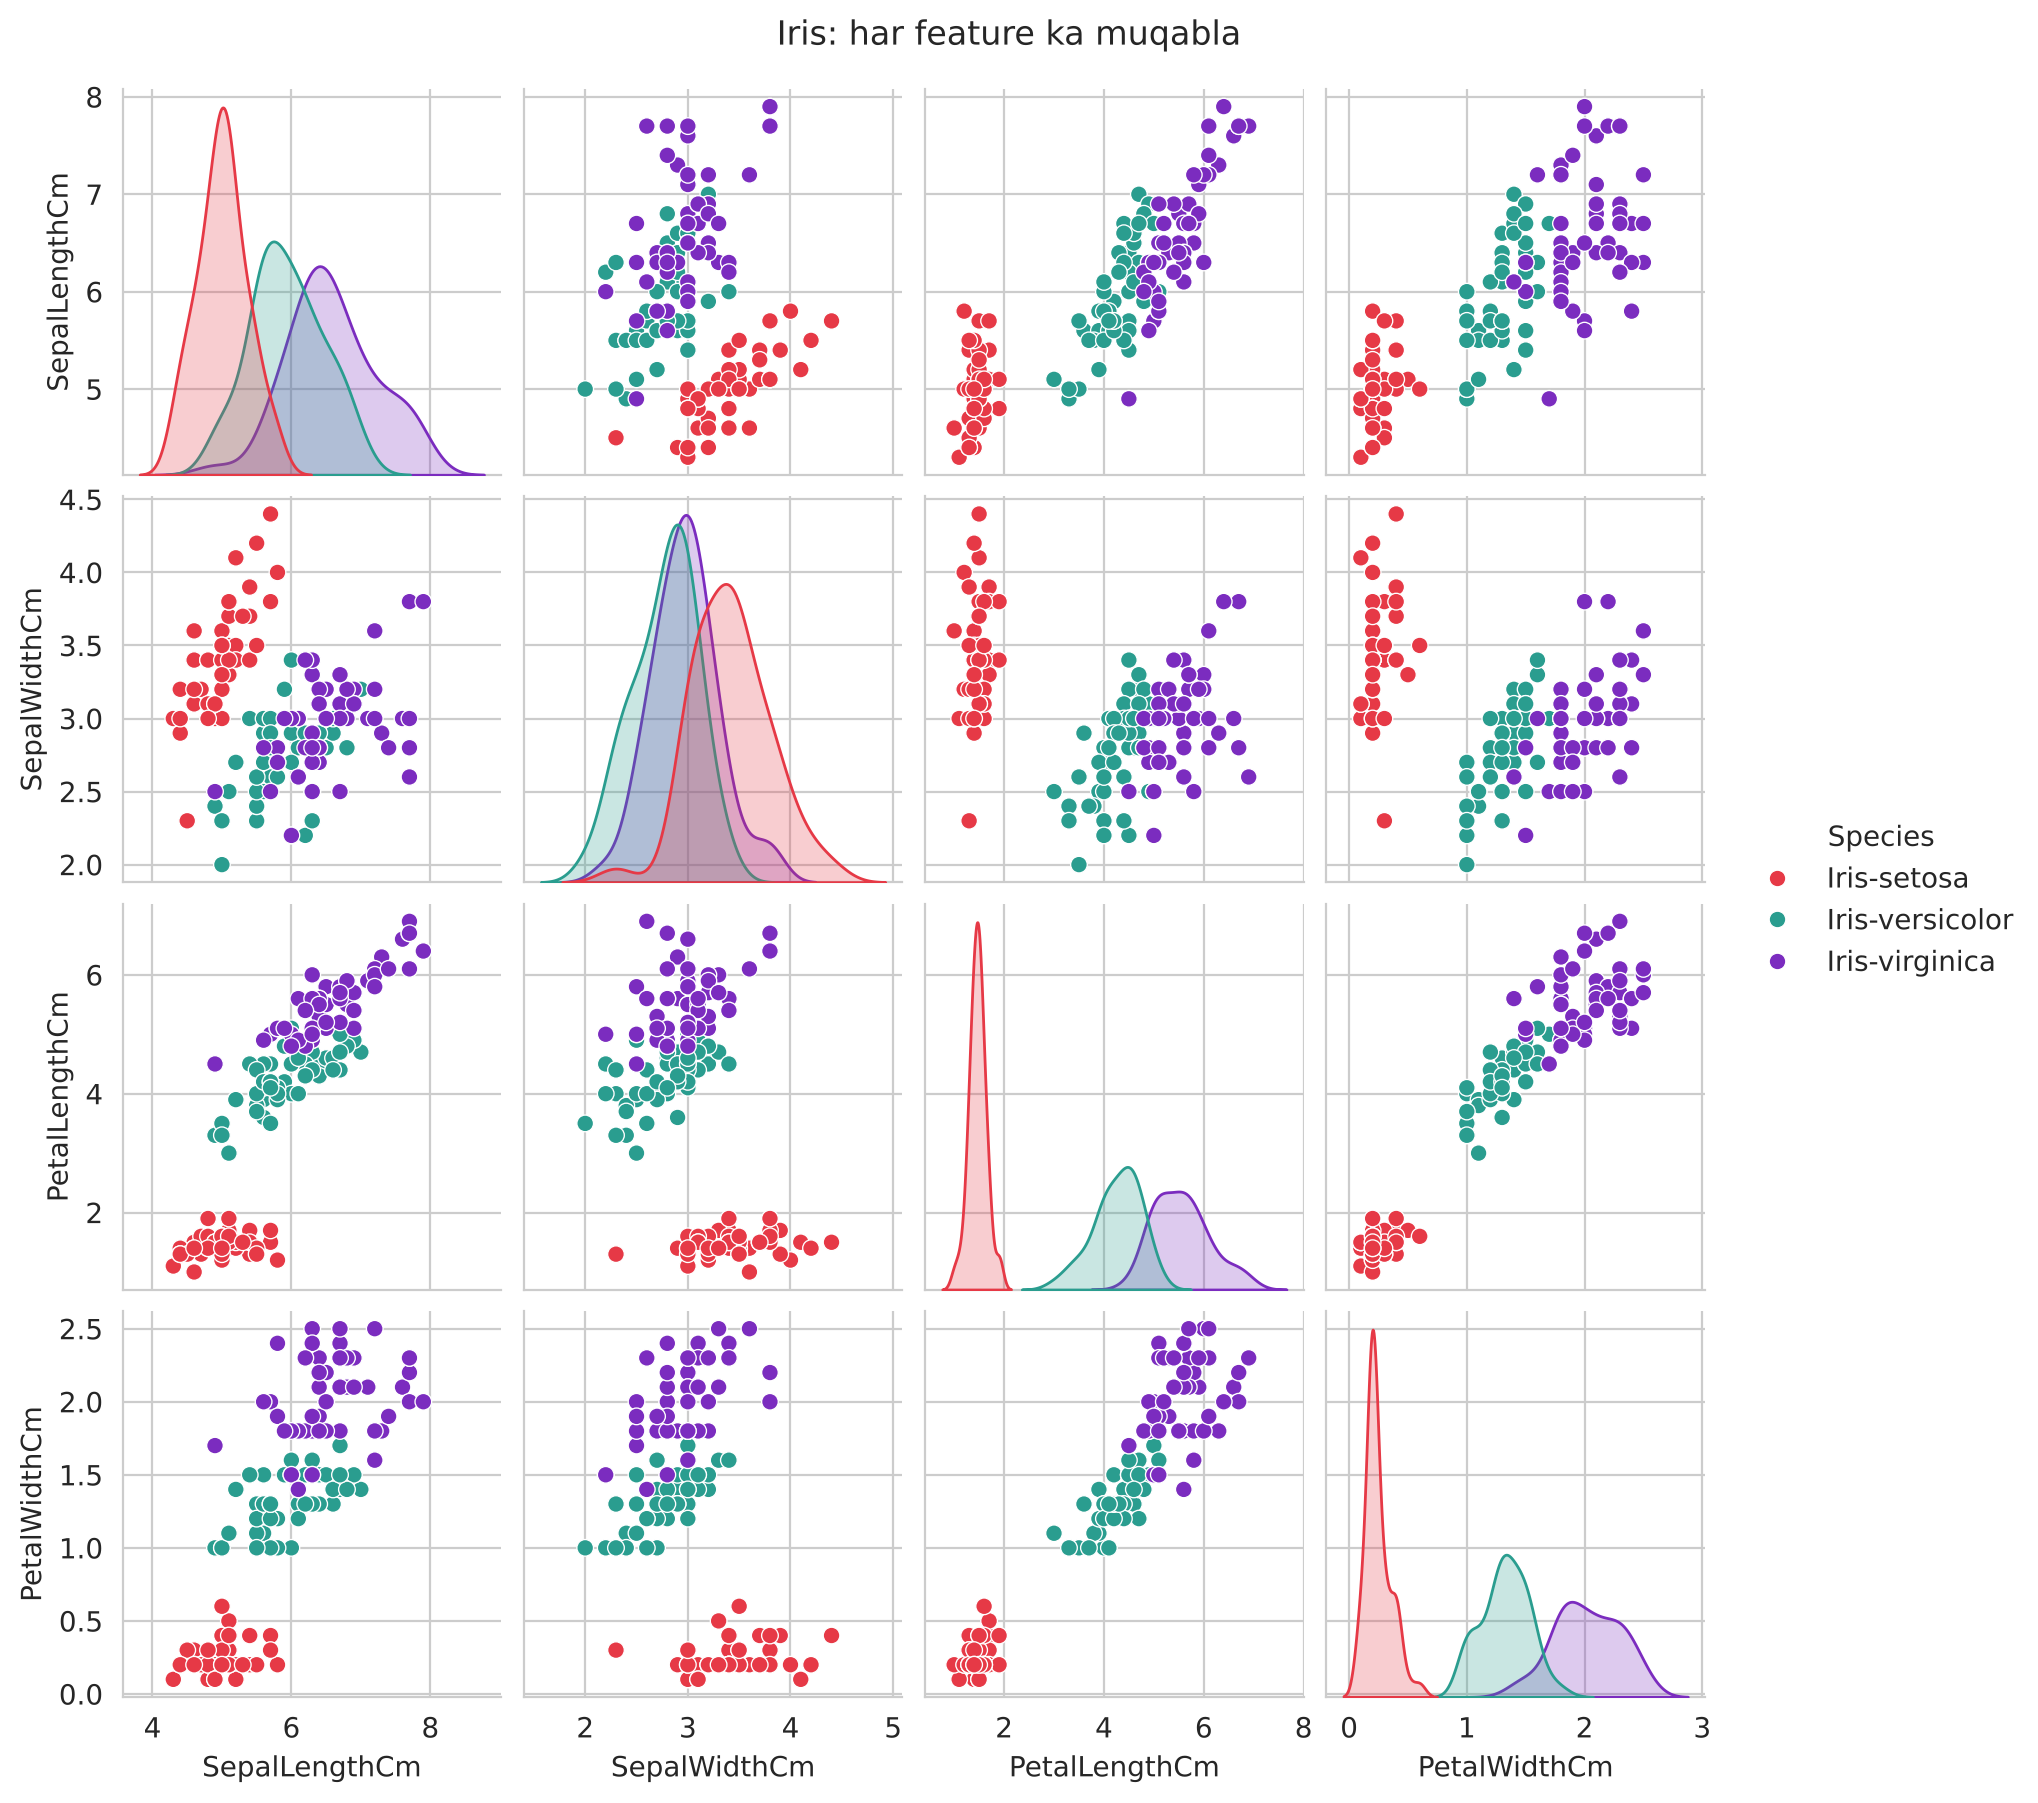

In [6]:
sns.pairplot(df, hue="Species", palette=["#E63946", "#2A9D8F", "#7B2CBF"], height=2.2)
plt.suptitle("Iris: har feature ka muqabla", y=1.02)
plt.show()

**Observation:** Petal Length aur Petal Width wale graphs dekho! 🌸 **Setosa (laal)** baqi dono se bilkul alag, akeli khari hai. Versicolor aur Virginica thore se milte hain lekin phir bhi kaafi had tak alag hain.

Matlab **Petal** ke naap shayad sab se kaam ke hain. Dekhte hain Decision Tree bhi yahi seekhta hai ya nahi!

---
## Step 4: Target ko numbers mein badalna (Label Encoding) 🔢

`Species` column mein text hai (Iris-setosa waghaira). Model ko numbers chahiye.

**Yaad hai** Polynomial wali class mein humne kaha tha ke features ke liay `LabelEncoder` theek nahi kyunke wo ghalat order bana deta hai? Lekin **target (y)** ke liay ye bilkul theek hai! Kyun? Kyunke model target ke numbers ko order nahi samajhta, sirf **alag alag naam** samajhta hai. 0, 1, 2 bas teen alag labels hain.

In [7]:
le = LabelEncoder()
df["Species_code"] = le.fit_transform(df["Species"])

pd.DataFrame({"Phool": le.classes_, "Number": range(len(le.classes_))})

,Phool,Number
0,Iris-setosa,0
1,Iris-versicolor,1
2,Iris-virginica,2


Label Encoder ko bhi baad mein save karein ge, taa ke model jab `2` bataye to hum wapis **"Iris-virginica"** padh sakein.

---
## Step 5: X, y aur Train/Test split ✂️

In [8]:
X = df.drop(columns=["Species", "Species_code"])
y = df["Species_code"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training phool:", len(X_train), "| Testing phool:", len(X_test))
print("\nTest mein har qism:", y_test.value_counts().sort_index().tolist())

Training phool: 120 | Testing phool: 30

Test mein har qism: [10, 10, 10]


`stratify=y` ki wajah se test mein teeno qismein barabar (10-10-10) hain. ✅

---
## Step 6: Tree "best sawal" kaise chunta hai? (Gini Impurity) 🧮

Tree ke paas hazaron mumkin sawal hain: "Petal Length <= 2?", "Sepal Width <= 3.1?" ... Wo kaise faisla karta hai kaunsa sawal sab se acha hai?

Jawab: Wo sawal jo data ko **sab se "saaf" (pure)** hisson mein baant de.

### Impurity kya hai? 🧺
Socho ek tokri mein phal hain:
- 🍎🍎🍎🍎 Saare seb ➜ **Bilkul saaf (Pure).** Impurity = 0
- 🍎🍌🍇🍎🍌🍇 Mila jula ➜ **Bohat ganda (Impure).** Impurity zyada

**Gini Impurity** isi "gandagi" ko naapti hai:

$$ Gini = 1 - (p_1^2 + p_2^2 + p_3^2) $$

Jahan $p$ har class ka hissa (fraction) hai. **Gini = 0** matlab bilkul pure, aur jitna zyada utna mila jula.

### Chalo haath se calculate karte hain ✋

In [9]:
def gini(counts):
    total = sum(counts)
    return 1 - sum((c / total) ** 2 for c in counts)

# Training data mein shuru mein har qism ke kitne phool hain
start = y_train.value_counts().sort_index().tolist()
print("Shuru mein (Setosa, Versicolor, Virginica):", start)
print(f"Gini = {gini(start):.3f}   <- bohat mila jula")

Shuru mein (Setosa, Versicolor, Virginica): [40, 40, 40]
Gini = 0.667   <- bohat mila jula


Ab ek sawal try karte hain: **"Petal Length <= 2.45?"** aur dekhte hain ke ye data ko kitna saaf karta hai.

In [10]:
left = y_train[X_train["PetalLengthCm"] <= 2.45].value_counts().reindex([0, 1, 2], fill_value=0).tolist()
right = y_train[X_train["PetalLengthCm"] > 2.45].value_counts().reindex([0, 1, 2], fill_value=0).tolist()

print("Haan wala hissa (Petal Length <= 2.45):", left, f" Gini = {gini(left):.3f}")
print("Nahi wala hissa (Petal Length >  2.45):", right, f" Gini = {gini(right):.3f}")

n = len(y_train)
weighted = sum(left) / n * gini(left) + sum(right) / n * gini(right)
print(f"\nSawal ke baad average Gini = {weighted:.3f}")
print(f"Gandagi kitni kam hui: {gini(start):.3f} -> {weighted:.3f}  ✅")

Haan wala hissa (Petal Length <= 2.45): [40, 0, 0]  Gini = 0.000
Nahi wala hissa (Petal Length >  2.45): [0, 40, 40]  Gini = 0.500

Sawal ke baad average Gini = 0.333
Gandagi kitni kam hui: 0.667 -> 0.333  ✅


**Kamaal!** Is ek sawal ne saare **Setosa ko alag** kar diya (Gini = 0, bilkul pure). Gandagi lagbhag **aadhi** ho gayi.

Decision Tree yahi kaam **har feature aur har mumkin value** ke liay karta hai, aur jo sawal gandagi **sab se zyada kam** kare, usay chun leta hai. Phir har hisse ke andar yahi dobara... jab tak hisse pure na ho jayein ya hum rok na dein.

> ℹ️ Gini ke ilawa ek aur tareeqa **Entropy** bhi hai (`criterion="entropy"`). Kaam same hai, formula thora alag. Aksar dono ka result lagbhag barabar aata hai.

---
## Step 7: Decision Tree ko Scaling ki zaroorat nahi! 🎉

KNN wali class mein scaling **lazmi** thi kyunke KNN distance naapta hai. Decision Tree distance nahi naapta, wo sirf **ek feature pe ek sawal** poochta hai: "Petal Length <= 2.45?". Agar hum centimeter ko millimeter bana dein to sawal bas "Petal Length <= 24.5?" ho jaye ga, jawab wohi rahe ga.

Chalo saabit karte hain:

In [11]:
tree_raw = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)

scaler = StandardScaler().fit(X_train)
tree_scaled = DecisionTreeClassifier(max_depth=3, random_state=42).fit(scaler.transform(X_train), y_train)

print(f"Baghair scaling accuracy: {tree_raw.score(X_test, y_test):.1%}")
print(f"Scaling ke sath accuracy: {tree_scaled.score(scaler.transform(X_test), y_test):.1%}")
print("\nBilkul same! Tree ko scaling se koi farq nahi parta ✅")

Baghair scaling accuracy: 96.7%
Scaling ke sath accuracy: 96.7%

Bilkul same! Tree ko scaling se koi farq nahi parta ✅


---
## Step 8: Overfitting: tree ko kab rokna hai? ✂️🌳

Agar tree ko na roka jaye to wo tab tak sawal poochta rahe ga jab tak **har ek phool** ka alag jawab na ban jaye. Ye pakka **ratta** hai (overfitting).

Isko rokne ke liay hyperparameters:

| Hyperparameter | Kaam | Misaal |
|---|---|---|
| `max_depth` | Zyada se zyada kitne sawal (manzilein) | `max_depth=3` ➜ 3 se zyada sawal nahi |
| `min_samples_leaf` | Har leaf mein kam se kam kitne phool hon | `5` ➜ 5 se kam phoolon ke liay alag faisla nahi |
| `criterion` | Gandagi kaise naapni hai | `"gini"` ya `"entropy"` |

Isko **pruning** (darakht ki kaant chhaant ✂️) bhi kehte hain, jaise mali faltu shaakhein kaat deta hai.

### Apni aankhon se dekhte hain 👀
Samajhne ke liay sirf 2 features (Petal Length aur Width) lete hain aur dekhte hain alag depth pe tree kaise ilaqay baant ta hai:

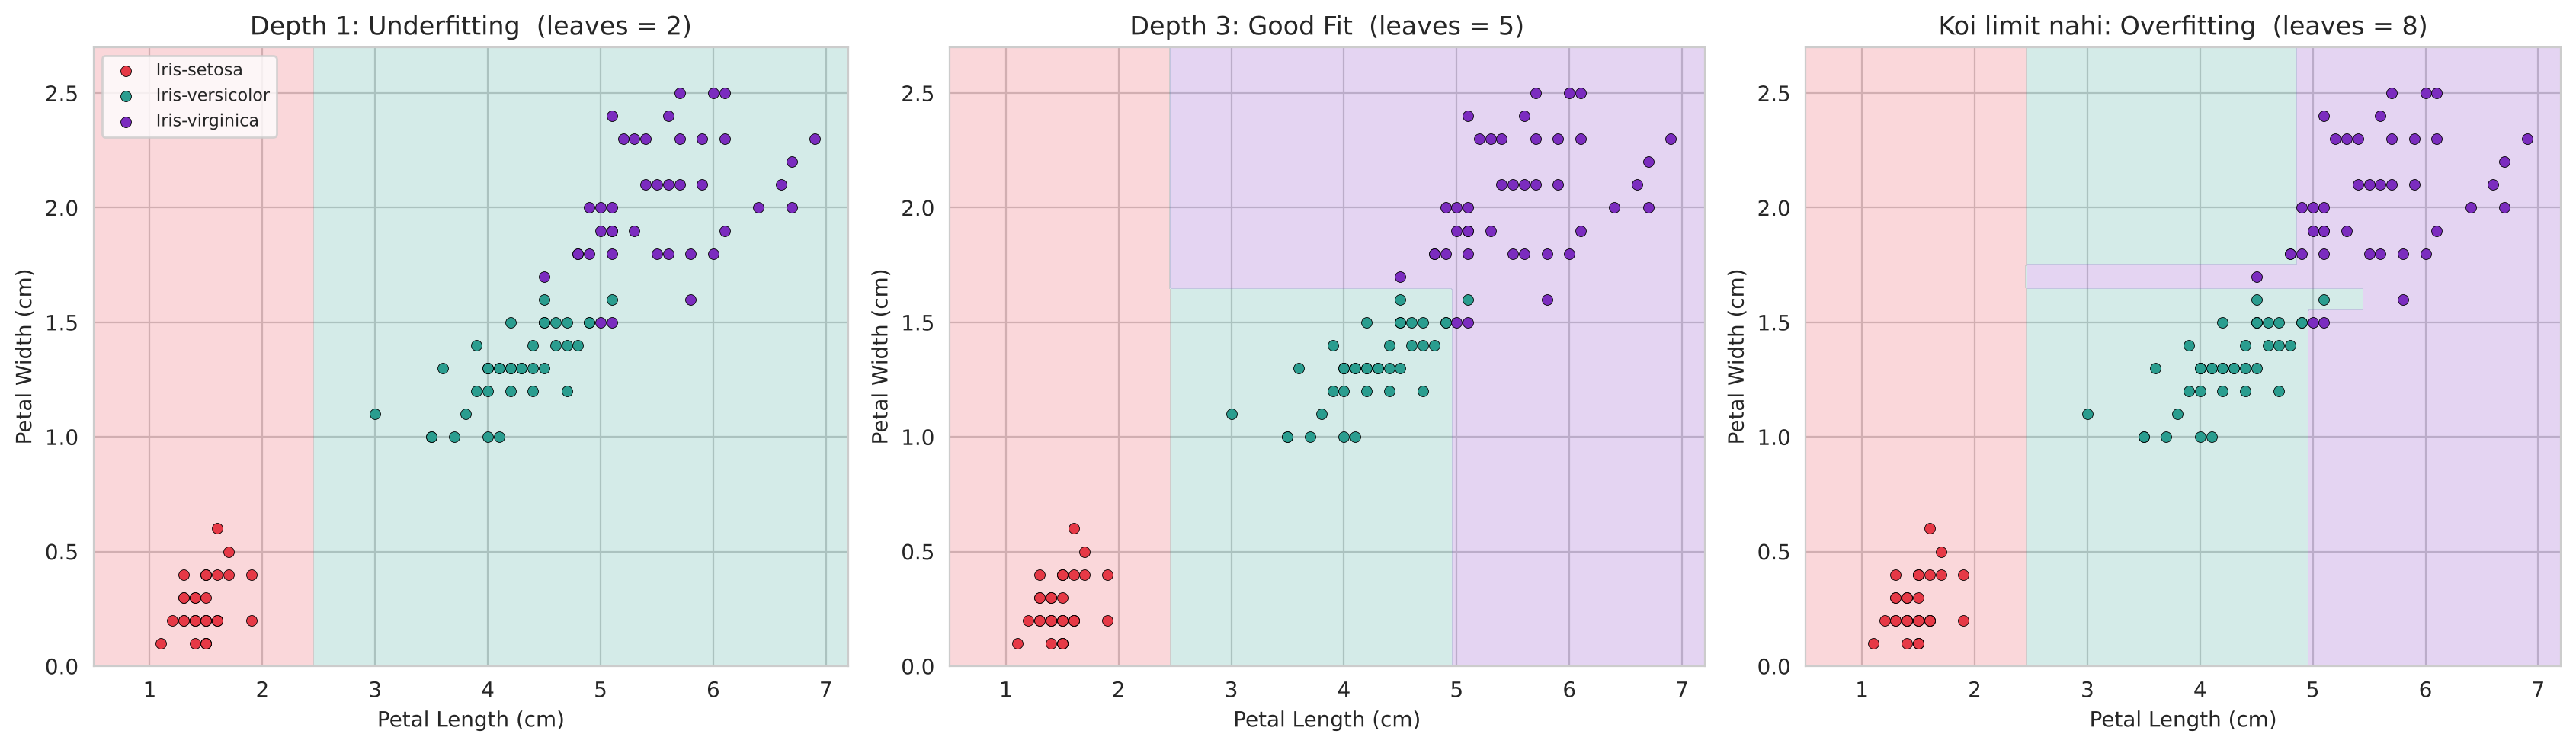

In [12]:
two = ["PetalLengthCm", "PetalWidthCm"]
X2 = X_train[two].values
xx, yy = np.meshgrid(np.linspace(0.5, 7.2, 400), np.linspace(0, 2.7, 400))
colors = ["#E63946", "#2A9D8F", "#7B2CBF"]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, depth, label in zip(axes, [1, 3, None], ["Depth 1: Underfitting", "Depth 3: Good Fit", "Koi limit nahi: Overfitting"]):
    t = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(X2, y_train)
    Z = t.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.2, levels=[-0.5, 0.5, 1.5, 2.5], colors=colors)
    for k in range(3):
        m = y_train == k
        ax.scatter(X2[m, 0], X2[m, 1], c=colors[k], s=25, edgecolor="k", linewidth=0.3, label=le.classes_[k])
    ax.set_title(f"{label}  (leaves = {t.get_n_leaves()})")
    ax.set_xlabel("Petal Length (cm)")
    ax.set_ylabel("Petal Width (cm)")
axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

**Graphs samjho:**
- **Depth 1:** Sirf ek sawal. Setosa to alag ho gaya, lekin Versicolor aur Virginica dono ek hi ilaqay mein. Tree ne kaam adhoora chhora (**underfitting**) 😴
- **Depth 3:** Saaf seedhi lakeerein, teeno qismein apne ilaqay mein ✅
- **Koi limit nahi:** Dekho chhote chhote patle ilaqay ban gaye, sirf ek do phoolon ko sahi karne ke liay. Ye **ratta** hai 🤪

> 💡 Note karo: Decision Tree ki boundaries hamesha **seedhi aur kone wali (seerhi jaisi)** hoti hain, kyunke har sawal sirf ek feature pe hota hai.

### Saare features ke sath depth ka asar

In [13]:
depths = [1, 2, 3, 4, 5, 6, None]
rows = []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=42)
    cv = cross_val_score(t, X_train, y_train, cv=5).mean()
    t.fit(X_train, y_train)
    rows.append({"max_depth": "None (limit nahi)" if d is None else d,
                 "Asal depth": t.get_depth(), "Leaves": t.get_n_leaves(),
                 "Training accuracy": round(t.score(X_train, y_train), 3),
                 "Cross Validation accuracy": round(cv, 3)})
depth_table = pd.DataFrame(rows)
depth_table

,max_depth,Asal depth,Leaves,Training accuracy,Cross Validation accuracy
0,1,1,2,0.667,0.667
1,2,2,3,0.967,0.925
2,3,3,5,0.983,0.933
3,4,4,7,0.992,0.942
4,5,5,8,1.000,0.942
5,6,5,8,1.000,0.942
6,None (limit nahi),5,8,1.000,0.942


Bina limit ke tree ki **training accuracy 100%** hai (har phool yaad!), lekin Cross Validation accuracy usse kam hai. Training aur CV ke beech ka ye farq hi **overfitting** ki pehchaan hai.

---
## Step 9: GridSearchCV: saari settings ek sath test karna 🔍

Pichli classes mein hum ek waqt mein **ek** hyperparameter loop se test karte thay (degree, C, K). Lekin yahan teen hain: `max_depth`, `min_samples_leaf`, `criterion`. Har combination haath se try karna mushkil hai!

**GridSearchCV** ye kaam khud karta hai: har combination pe **Cross Validation** chalata hai aur best bata deta hai.

Hamare grid mein 6 × 4 × 2 = **48 combinations** hain, aur har ek pe 5-fold CV, yani **240 baar** training! Ye sab ek line mein. 🚀

In [14]:
param_grid = {
    "max_depth": [1, 2, 3, 4, 5, None],
    "min_samples_leaf": [1, 2, 5, 10],
    "criterion": ["gini", "entropy"]
}

grid = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=5, scoring="accuracy")
grid.fit(X_train, y_train)

print("Best settings:", grid.best_params_)
print(f"Best CV accuracy: {grid.best_score_:.3f}")

Best settings: {'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 1}
Best CV accuracy: 0.942


In [15]:
results = pd.DataFrame(grid.cv_results_)
top = (results[["param_max_depth", "param_min_samples_leaf", "param_criterion", "mean_test_score"]]
       .sort_values("mean_test_score", ascending=False)
       .head(10)
       .rename(columns={"param_max_depth": "max_depth", "param_min_samples_leaf": "min_samples_leaf",
                        "param_criterion": "criterion", "mean_test_score": "CV accuracy"}))
top["CV accuracy"] = top["CV accuracy"].round(3)
top

,max_depth,min_samples_leaf,criterion,CV accuracy
12,4,1,gini,0.942
16,5,1,gini,0.942
20,None,1,gini,0.942
9,3,2,gini,0.933
17,5,2,gini,0.933
21,None,2,gini,0.933
8,3,1,gini,0.933
13,4,2,gini,0.933
40,5,1,entropy,0.933
11,3,10,gini,0.925


### Ek samajhdari wala faisla: Simple model chuno 🧠
Upar ki list dekho. Bohat se combinations ka score **lagbhag barabar** hai. Hamare paas sirf 120 training phool hain, to 0.008 ka farq matlab poori Cross Validation mein **sirf ek phool** ka farq!

Jab scores itne qareeb hon to ML mein ek mashhoor usool hai:

> **Jo model sab se simple ho aur best se 1% ke andar ho, wohi chuno.** (Occam's Razor)

Simple tree naye data pe zyada bharosay ke qabil hota hai aur samajhna bhi asaan. Ye faisla hum **test data dekhe baghair** sirf CV scores se karte hain:

In [16]:
best_score = depth_table["Cross Validation accuracy"].max()
good_enough = depth_table[(depth_table["Cross Validation accuracy"] >= best_score - 0.01) &
                          (depth_table["max_depth"] != "None (limit nahi)")]
chosen_depth = int(good_enough["max_depth"].min())

print(f"Best CV accuracy: {best_score:.3f}")
print(f"Sab se chhoti depth jo 1% ke andar hai: {chosen_depth}")

Best CV accuracy: 0.942
Sab se chhoti depth jo 1% ke andar hai: 3


---
## Step 10: Final model train karna aur Evaluation 🏁

In [17]:
model = DecisionTreeClassifier(criterion="gini", max_depth=chosen_depth, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.1%}")
print(f"Tree ki depth: {model.get_depth()}  |  Leaves (aakhri faisle): {model.get_n_leaves()}")

Test Accuracy: 96.7%
Tree ki depth: 3  |  Leaves (aakhri faisle): 5


### 3×3 Confusion Matrix 🧩
Binary mein 2×2 matrix thi. Ab 3 classes hain to **3×3**. **Diagonal** (upar baaein se neeche daaein) pe sahi jawab hain, baqi sab ghaltiyan.

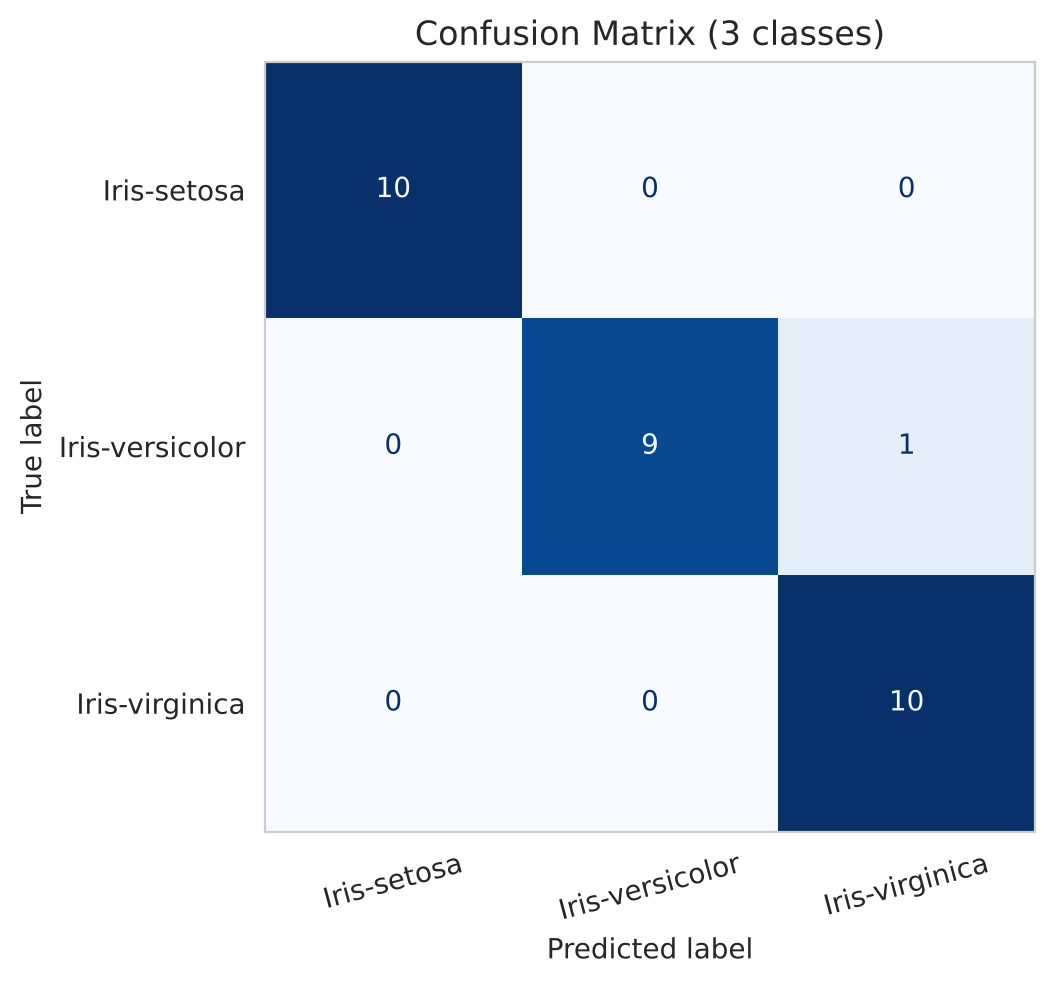

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



In [18]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=le.classes_).plot(cmap="Blues", colorbar=False)
plt.title("Confusion Matrix (3 classes)")
plt.xticks(rotation=15)
plt.grid(False)
plt.show()

print(classification_report(y_test, y_pred, target_names=le.classes_))

**Samjho:** Setosa **100% sahi**, jaise pairplot mein dekha tha, wo bilkul alag thi. Jo thori bohat ghalti hai wo **Versicolor aur Virginica** ke beech hai, kyunke ye dono thore milte julte hain. Bilkul wohi jo graph mein nazar aaya tha!

---
## Step 11: Tree ko dekhna 🌳👀

Decision Tree ki sab se bari khoobi: ye **"black box" nahi** hai. Hum dekh sakte hain model ne **bilkul kya seekha**.

### Graph ki shakal mein
Har box mein:
- **Sawal** (jaise `PetalLengthCm <= 2.45`)
- **gini:** us box ki gandagi
- **samples:** kitne phool us box tak pohanche
- **value:** har qism ke kitne phool [Setosa, Versicolor, Virginica]
- **class:** agar yahan ruk jayein to faisla kya hoga
- **Rang:** jitna gehra, utna pure

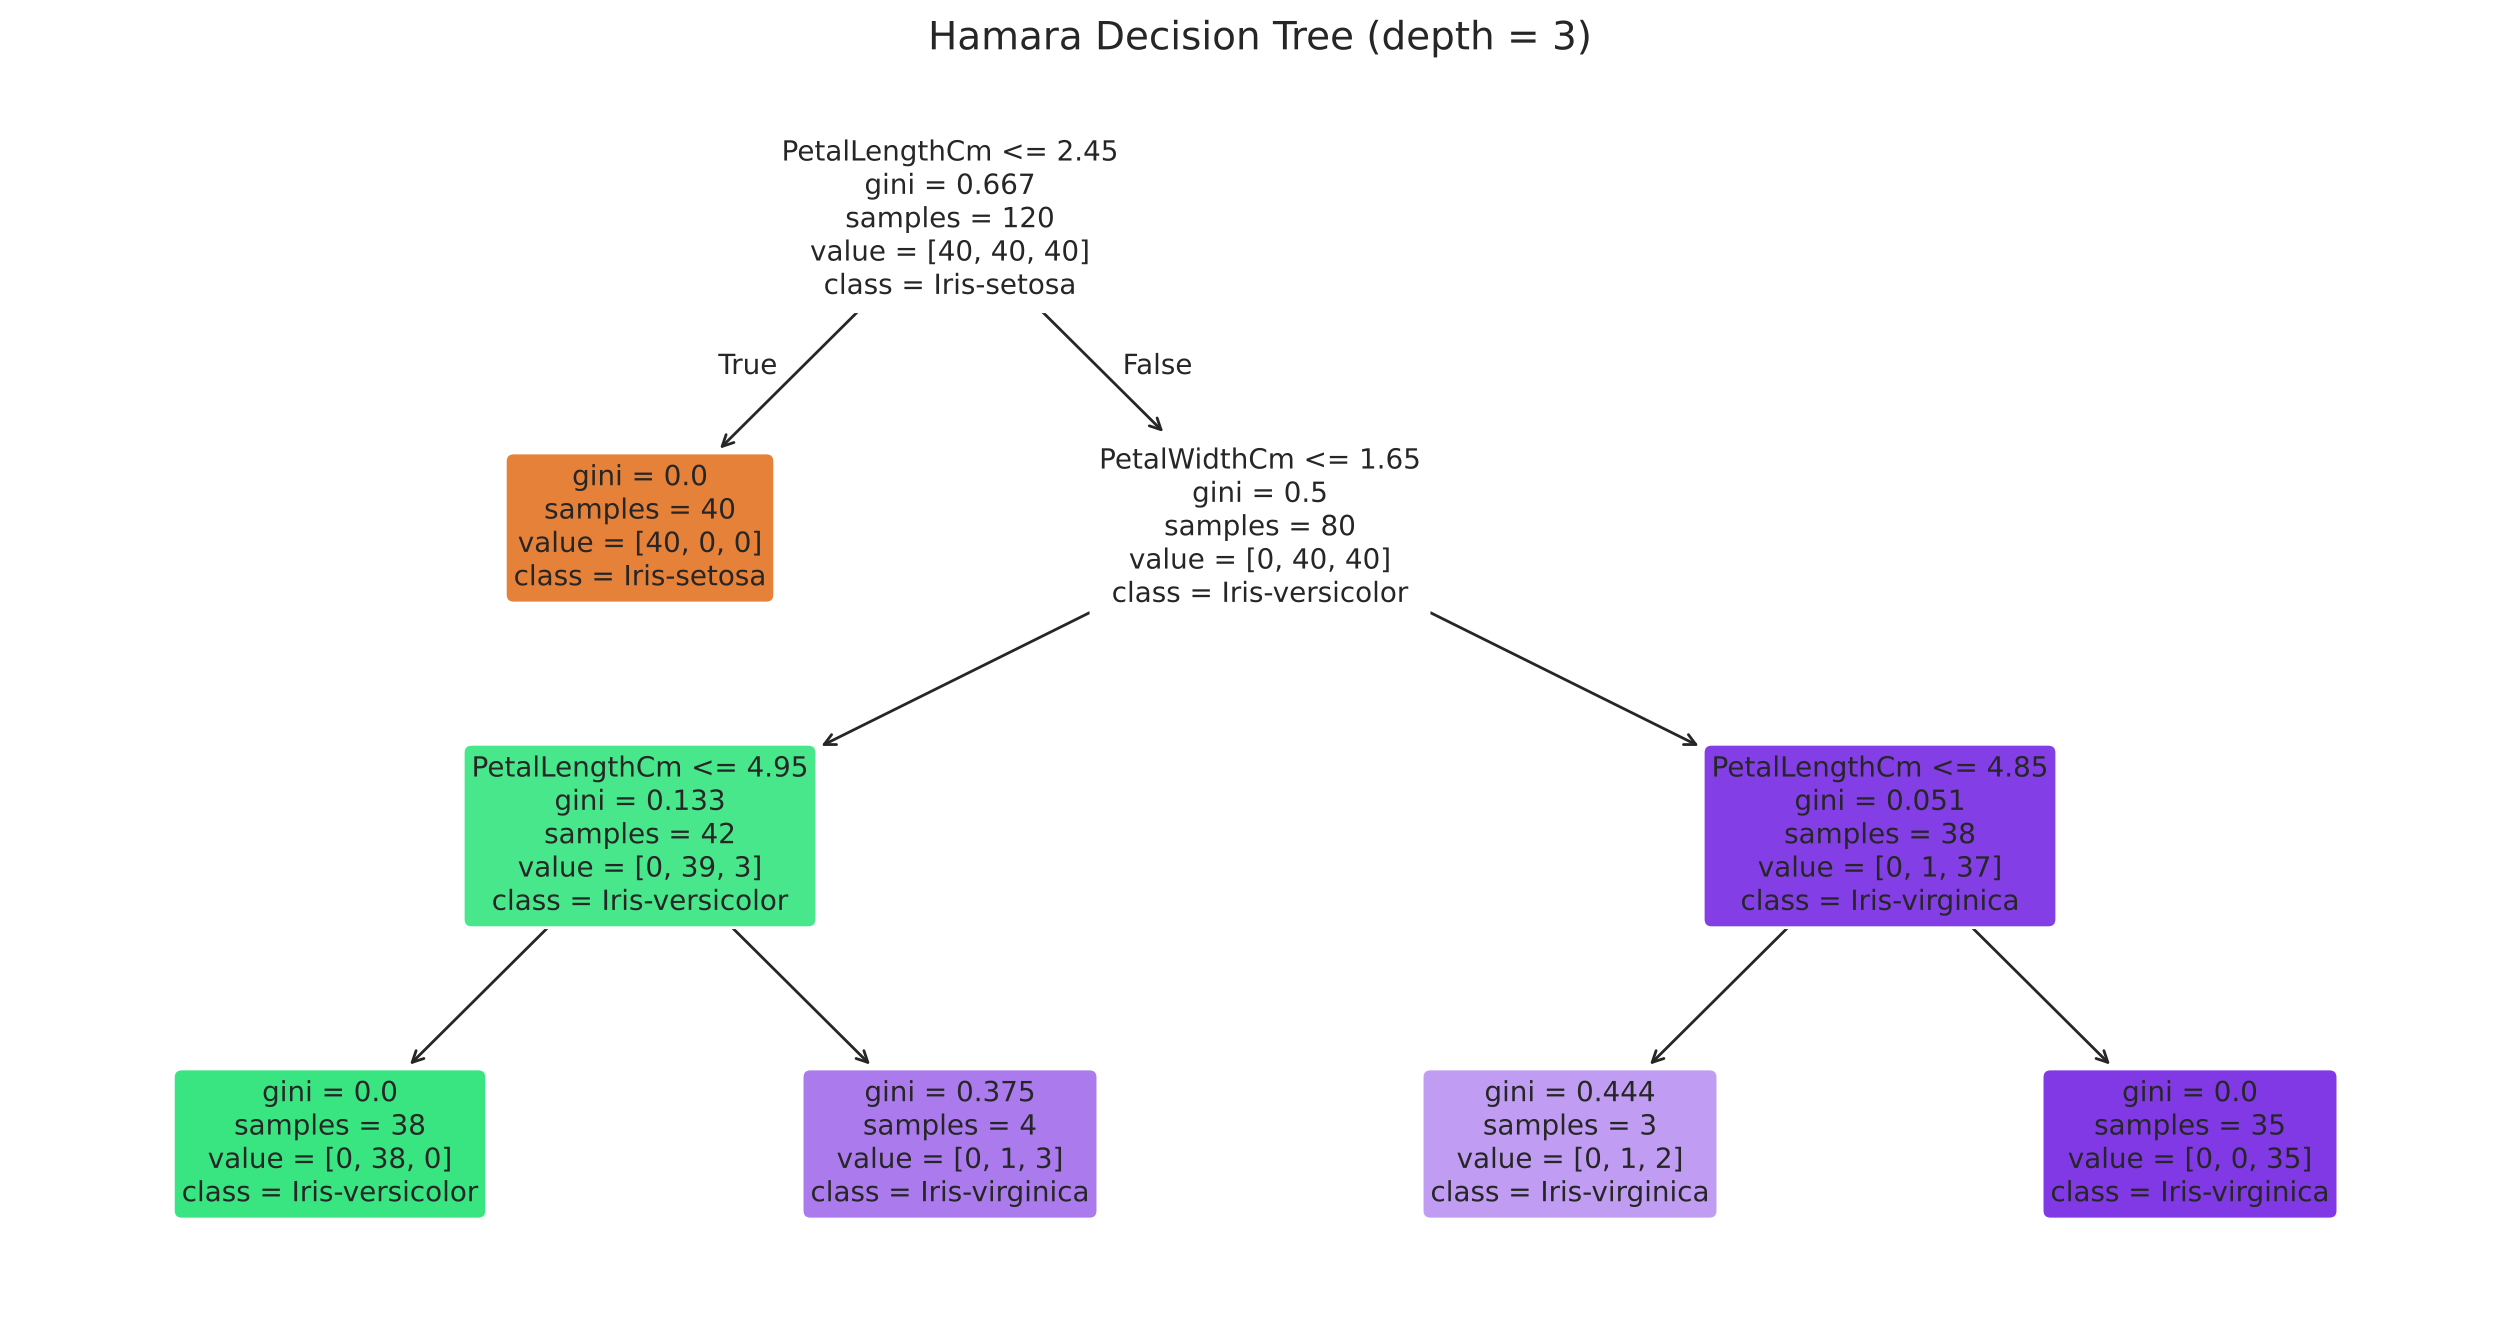

In [19]:
plt.figure(figsize=(16, 8))
plot_tree(model, feature_names=X.columns, class_names=le.classes_,
          filled=True, rounded=True, fontsize=10, impurity=True)
plt.title(f"Hamara Decision Tree (depth = {model.get_depth()})", fontsize=14)
plt.show()

Root node mein **wohi sawal** hai jo humne Step 6 mein haath se check kiya tha: `PetalLengthCm <= 2.45`! Aur baaein taraf Setosa ka box bilkul pure hai (gini = 0). 🎯

### If-Else rules ki shakal mein 📜
Yehi tree simple **if-else** ke rules mein bhi likha ja sakta hai. Ye rules aap kisi bhi app mein bina ML ke bhi laga sakte ho!

In [20]:
print(export_text(model, feature_names=list(X.columns), class_names=list(le.classes_)))

|--- PetalLengthCm <= 2.45
|   |--- class: Iris-setosa
|--- PetalLengthCm >  2.45
|   |--- PetalWidthCm <= 1.65
|   |   |--- PetalLengthCm <= 4.95
|   |   |   |--- class: Iris-versicolor
|   |   |--- PetalLengthCm >  4.95
|   |   |   |--- class: Iris-virginica
|   |--- PetalWidthCm >  1.65
|   |   |--- PetalLengthCm <= 4.85
|   |   |   |--- class: Iris-virginica
|   |   |--- PetalLengthCm >  4.85
|   |   |   |--- class: Iris-virginica



**Isko aise parho:** "Agar Petal Length 2.45 se kam hai to **Setosa**. Warna agar Petal Width 1.65 se kam hai to..." Bilkul insaanon jaisa sochne ka tareeqa! 🧠

> 🤓 Ek dilchasp baat: Neeche wali shaakh mein `PetalLengthCm <= 4.85` ke dono taraf **Virginica** hi hai! Tree ne ye sawal isliay poocha kyunke is se boxes thore aur "saaf" ho gaye (gini kam hua), chahe aakhri faisla same raha. Tree sirf gandagi kam karne ki koshish karta hai.

### Feature Importance 🔎
Kaunsa feature faisle mein kitna kaam aaya? Decision Tree ye bhi batata hai (har feature ne kitni gandagi kam ki).

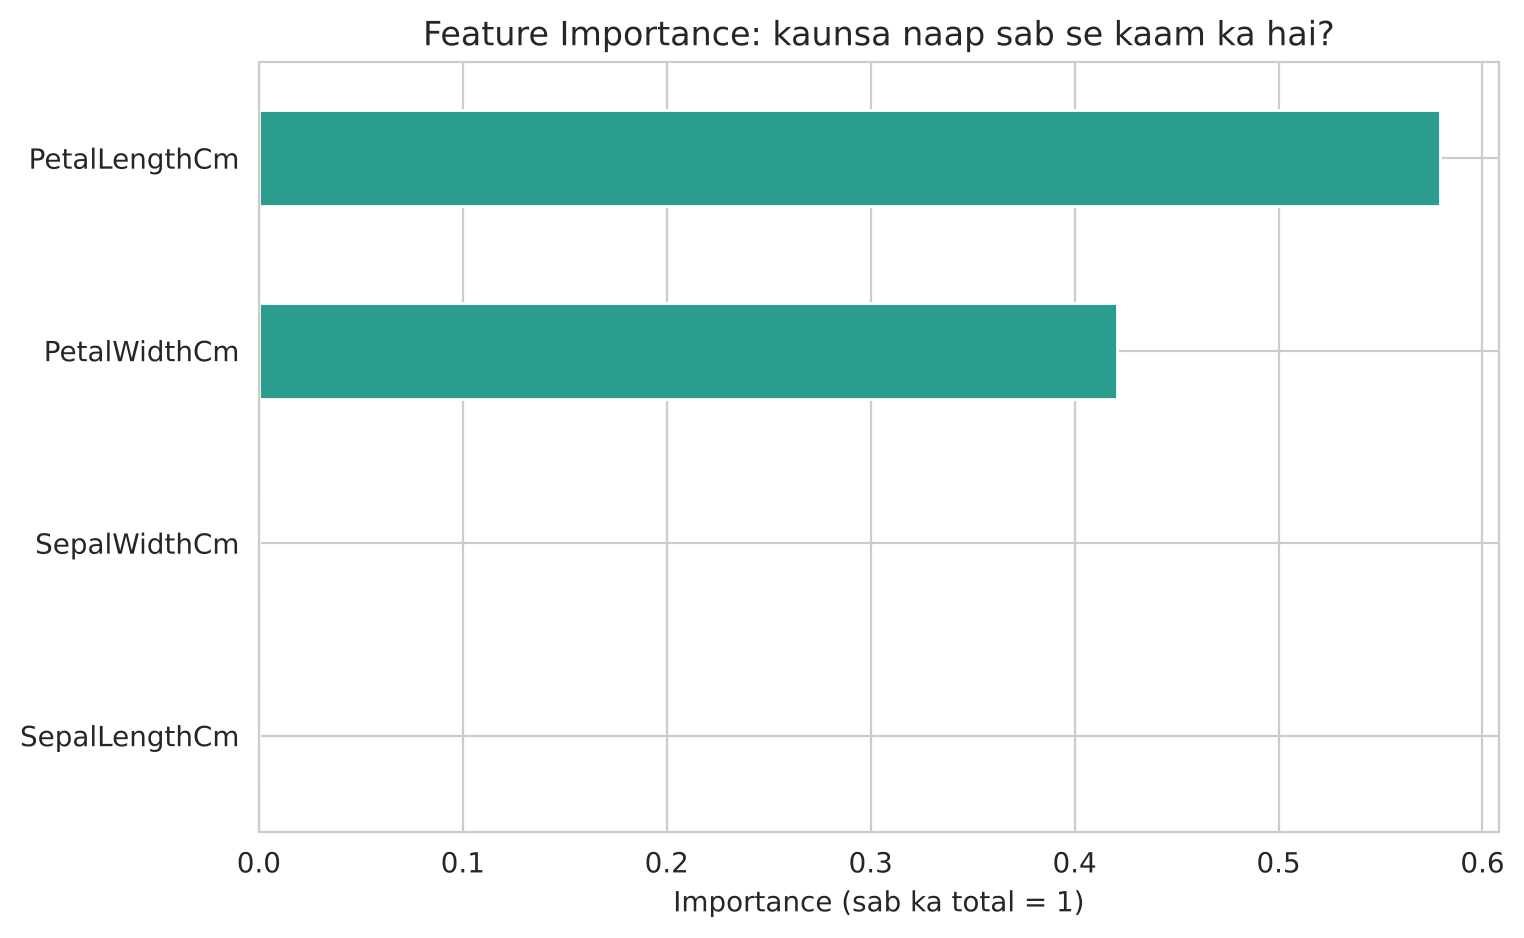

PetalLengthCm   57.9%
PetalWidthCm    42.1%
SepalWidthCm    0.0%
SepalLengthCm   0.0%


In [21]:
importance = pd.Series(model.feature_importances_, index=X.columns).sort_values()

importance.plot(kind="barh", color=["#adb5bd", "#adb5bd", "#2A9D8F", "#2A9D8F"])
plt.title("Feature Importance: kaunsa naap sab se kaam ka hai?")
plt.xlabel("Importance (sab ka total = 1)")
plt.show()

for feat, val in importance.sort_values(ascending=False).items():
    print(f"{feat:<15} {val:.1%}")

Jo pairplot mein nazar aaya tha, tree ne bhi khud wohi seekha: **Petal ke naap** hi sab kuch hain. Hamare depth 3 wale tree ne Sepal ka ek bhi sawal nahi poocha (0%). 🌸

---
## Step 12: Ab tak ke saare models ka muqabla 📊

| | Linear / Polynomial | Logistic | KNN | **Decision Tree** |
|---|---|---|---|---|
| Kaam | Number predict | Class predict | Class predict | **Class predict** (Regression bhi kar sakta hai) |
| Kaise sochta hai | Line / curve | Sigmoid probability | Padosiyon ka vote | **Sawal pe sawal** |
| Scaling zaroori? | Polynomial mein haan | Haan | **Lazmi** | **Nahi** ✅ |
| Samajhna | Asaan | Theek | Asaan | **Sab se asaan** (rules dekh sakte ho) |
| Main hyperparameters | Degree | C, max_iter | K, weights | **max_depth, min_samples_leaf, criterion** |

### Decision Tree ke fayde aur nuqsaan

| ✅ Fayde | ❌ Nuqsaan |
|---|---|
| Samajhna aur samjhana bohat asaan | Bohat jaldi **overfit** ho jata hai |
| Scaling ki zaroorat nahi | Data mein chhoti si tabdeeli se poora tree badal sakta hai |
| Numbers aur categories dono handle | Boundaries sirf seedhi aur kone wali |
| Multi-class khud handle karta hai | Akela tree aksar sab se zyada accurate nahi hota |

> 🌲🌲🌲 **Agli class ka teaser:** Agar ek tree ghalti karta hai, to kya ho agar hum **100 alag trees** bana kar unka vote lein? Isko **Random Forest** kehte hain!

---
# 💾 Step 13: Model aur Label Encoder ko Pickle mein save karna

Model sirf numbers (0, 1, 2) batata hai. Unko wapis phool ke naam mein badalne ke liay **Label Encoder** bhi chahiye. Isliay dono ek package mein save karte hain.

In [22]:
model_package = {
    "model": model,
    "label_encoder": le,
    "features": list(X.columns)
}

with open("decision_tree_iris_model.pkl", "wb") as file:
    pickle.dump(model_package, file)

print("Model save ho gaya: decision_tree_iris_model.pkl ✅")

Model save ho gaya: decision_tree_iris_model.pkl ✅


### Load kar ke naye phool ki qism batana 🌼
Function sirf qism nahi, balkay **raasta** bhi batata hai ke tree ne kaunse sawal pooch kar faisla kiya. Decision Tree ki yahi to khoobi hai!

In [23]:
with open("decision_tree_iris_model.pkl", "rb") as file:
    loaded = pickle.load(file)

def identify_flower(sepal_length, sepal_width, petal_length, petal_width, package=loaded):
    flower = pd.DataFrame([[sepal_length, sepal_width, petal_length, petal_width]],
                          columns=package["features"])
    tree = package["model"]

    code = tree.predict(flower)[0]
    name = package["label_encoder"].inverse_transform([code])[0]
    confidence = tree.predict_proba(flower)[0].max()

    # Tree ne kaunse sawal poochay?
    node_path = tree.decision_path(flower).indices
    t = tree.tree_
    print("Tree ke sawal:")
    for node in node_path:
        if t.children_left[node] == -1:   # leaf pe pohanch gaye
            break
        feat = package["features"][t.feature[node]]
        value = flower.iloc[0][feat]
        answer = "Haan" if value <= t.threshold[node] else "Nahi"
        print(f"   Kya {feat} <= {t.threshold[node]:.2f} hai?  ({feat} = {value})  ->  {answer}")
    print(f"Faisla: {name}  (yaqeen: {confidence:.0%})\n")


identify_flower(5.1, 3.5, 1.4, 0.2)   # chhoti pankhriyan
identify_flower(6.0, 2.9, 4.5, 1.4)   # darmiyani
identify_flower(6.9, 3.1, 5.8, 2.2)   # bari pankhriyan

Tree ke sawal:
   Kya PetalLengthCm <= 2.45 hai?  (PetalLengthCm = 1.4)  ->  Haan
Faisla: Iris-setosa  (yaqeen: 100%)

Tree ke sawal:
   Kya PetalLengthCm <= 2.45 hai?  (PetalLengthCm = 4.5)  ->  Nahi
   Kya PetalWidthCm <= 1.65 hai?  (PetalWidthCm = 1.4)  ->  Haan
   Kya PetalLengthCm <= 4.95 hai?  (PetalLengthCm = 4.5)  ->  Haan
Faisla: Iris-versicolor  (yaqeen: 100%)

Tree ke sawal:
   Kya PetalLengthCm <= 2.45 hai?  (PetalLengthCm = 5.8)  ->  Nahi
   Kya PetalWidthCm <= 1.65 hai?  (PetalWidthCm = 2.2)  ->  Nahi
   Kya PetalLengthCm <= 4.85 hai?  (PetalLengthCm = 5.8)  ->  Nahi
Faisla: Iris-virginica  (yaqeen: 100%)



> ⚠️ Kabhi bhi anjaan insaan ki di hui `.pkl` file load na karo, usme chhupa code ho sakta hai. 🔒

> 💡 **Colab mein file download karni ho:**
> ```python
> from google.colab import files
> files.download("decision_tree_iris_model.pkl")
> ```

---
## 📚 Summary: Aaj humne kya seekha

1. **Decision Tree:** "20 sawal" ki tarah sawal pe sawal pooch kar faisla. Root, Internal Node, Branch, Leaf
2. **Multi-class Classification:** 2 se zyada classes (yahan 3 phool)
3. **Gini Impurity:** Gandagi naapne ka tareeqa. Tree wo sawal chunta hai jo gandagi sab se zyada kam kare
4. **Scaling ki zaroorat nahi**, kyunke tree distance nahi, sirf ek feature pe sawal poochta hai
5. **Overfitting:** Bina limit ke tree ratta maarta hai. `max_depth` aur `min_samples_leaf` se pruning ✂️
6. **GridSearchCV:** Saare hyperparameter combinations ek sath Cross Validation se test
7. **Simple model chuno** jab scores qareeb hon (Occam's Razor)
8. **3×3 Confusion Matrix**, tree ka graph, if-else rules aur Feature Importance
9. Model + Label Encoder ko Pickle mein save, aur faisle ka **raasta** dikhana

---
## ✍️ Homework / Practice

1. Step 6 mein `PetalLengthCm <= 2.45` ki jagah `SepalWidthCm <= 3.0` ka Gini nikalo. Ye sawal acha hai ya bura? Kyun?
2. Final model mein `criterion="entropy"` kar ke dekho. Tree ka graph badla?
3. `max_depth=None` ke sath final model banao aur `plot_tree` se dekho. Kitni leaves aayin? Test accuracy kya aayi?
4. Sirf 2 features (`PetalLengthCm`, `PetalWidthCm`) se model banao. Accuracy kitni giri? (Hint: Feature Importance yaad karo!)
5. **Socho:** Agar aap ek bank ke liay loan approve karne ka model bana rahe ho, to Decision Tree ka kya fayda hoga jo KNN mein nahi? (Hint: customer poochay "mera loan kyun reject hua?")

**Shabash! Aapne pehla aisa model bana liya jo apna faisla khud samjha sakta hai. 🎓**